# XRD — Phase identification, Rietveld refinement and crystallite size of the coprecipitated MgFe$_2$O$_4$ sample

**Samples**
- **XRD1** (measured 2026-09-24): first pass, after calcination at **400 °C**; 20–80° 2θ, 2015 points.
- **XRD2** (measured 2026-10-14): second pass, after additional recalcination at **600 °C**; 10–75° 2θ, 2183 points.

Instrument: Bruker D8 Advance, Cu Kα (λ = 1.5406 Å), LynxEye PSD, locked-coupled θ/2θ scan (metadata from the `.brml` containers).

**Pipeline**
1. Extract raw counts from the Bruker XML (`<Datum>t,channel,2θ,θ,counts</Datum>`).
2. Preprocess: 5-point rolling-median despike only. **The background is NOT pre-subtracted for the Rietveld fit** — it is refined as a 6-term Chebyshev polynomial inside the model, so the agreement indices are computed against raw counts with counting-statistics weights.
3. Screen ALL reference CIFs in `analysis/rietveld/reference/` (29 hematite, 50 spinel) by single-phase fit cost → select the best.
4. Two-phase Rietveld-style refinement: per-phase scale, isotropic lattice scale (sin θ scaling), single FWHM, zero shift, pseudo-Voigt (η = 0.3), 6-term Chebyshev background. Multi-start over scale ratios to avoid false minima.
5. Report Rwp, Rexp, χ², GoF; Scherrer and Williamson–Hall per reflection with correct unit handling.

In [1]:
import numpy as np, pandas as pd, re, math, itertools
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter
from scipy.optimize import least_squares, curve_fit
from scipy.signal import find_peaks
from pymatgen.core import Structure
from pymatgen.analysis.diffraction.xrd import XRDCalculator
from pathlib import Path

ROOT = Path('../..').resolve()
FIGS = ROOT/'article/figs'; FIGS.mkdir(exist_ok=True, parents=True)
REF  = ROOT/'analysis/rietveld/reference'
LAM  = 1.5406   # Å, Cu Kα1
ETA  = 0.3      # pseudo-Voigt mixing (fixed)
NBG  = 6        # Chebyshev background terms
BINST = 0.05    # instrument FWHM, deg (D8/LynxEye typical)

def extract(path):
    xml = Path(path).read_text()
    rows = re.findall(r'<Datum>([^<]+)</Datum>', xml)
    d = pd.DataFrame([r.split(',') for r in rows],
                     columns=['t','ch','tt','th','I']).astype(float)
    return d

RAW = {'XRD1 (400°C)': ROOT/'data/XRD/XRD1/MgFe2O4/RawData0.xml',
       'XRD2 (600°C)': ROOT/'data/XRD/XRD2/MgFe2O4/Experiment0/RawData0.xml'}

# ---- preprocessing: despike only (keep raw counts for Rietveld)
data = {}
for k, p in RAW.items():
    d = extract(p)
    I = d.I.values
    Id = median_filter(I, size=5)
    nspk = int(np.abs(I - Id).sum() > 0 and np.sum(np.abs(I-Id) > 5*np.std(I-Id)))
    data[k] = dict(tt=d.tt.values, I=Id, nspk=nspk)
    print(f'{k}: {len(d)} pts, {d.tt.min():.1f}-{d.tt.max():.1f}°, '
          f'{nspk} despiked pts, Imax={I.max():.0f} counts')

XRD1 (400°C): 2015 pts, 20.0-80.0°, 0 despiked pts, Imax=4630 counts
XRD2 (600°C): 2183 pts, 10.0-75.0°, 2 despiked pts, Imax=5976 counts


## 1. CIF screening — which references, and why

Every hematite (`Fe2_O3/`) and spinel (`mgfe2o4/`) CIF in the repo is fitted as a **single phase** against XRD2 (fixed moderate FWHM, Gaussian, crude constant background). Ranking by fit cost:

- **Hematite**: `9015964.cif` (ICSD, R-3c, a = 5.0356 Å) ranks first; `2101168`/`2101167` are equivalent cells. All give the same peak *positions*; they differ in the cation/O coordinates → slightly different intensities. `9015964` is the best match to the observed intensities (its 104/110 ratio matches).
- **Spinel**: all Fd-3m CIFs share identical positions (a ≈ 8.36–8.48 Å); they differ in **inversion parameter** (normal vs inverse MgFe$_2$O$_4$) → different (220)/(400) intensities. The screening prefers cells near a ≈ 8.38 Å with largely inverse character; `9001446.cif` (a = 8.3805 Å) is chosen, and the refinement below confirms the refined a lands at 8.36–8.37 Å.

(Magnetite Fe$_3$O$_4$ and MgO references were also simulated — their diagnostic lines at 18.3°/30.1°/36.9°/42.9°/62.3° do not match the non-overlapping observed peaks, so they are excluded.)

In [2]:
xrdc = XRDCalculator(wavelength=LAM)
def ref_pattern(cif, ttmax=85):
    s = Structure.from_file(str(cif))
    p = xrdc.get_pattern(s, two_theta_range=(8, ttmax))
    o = np.argsort(p.x)
    return np.array(p.x)[o], np.array(p.y)[o], s

def screen(cifs, tt, I):
    base = np.percentile(I, 10)
    rows = []
    for f in sorted(cifs):
        try:
            px, py, s = ref_pattern(f)
            m = (px > tt.min()) & (px < tt.max())
            def model(q):
                sig = q[1]/2.3548
                y = np.zeros_like(tt)
                for p, i in zip(px[m], py[m]):
                    y += i*np.exp(-0.5*((tt-p-q[2])/sig)**2)
                return q[0]*y + base
            r = least_squares(lambda q: model(q)-I, [10, 0.3, 0.0],
                             bounds=([0, 0.1, -0.2], [1e4, 1.0, 0.2]))
            rows.append((f.name, Path(f).parent.name, round(s.lattice.abc[0], 4), r.cost))
        except Exception:
            pass
    return pd.DataFrame(rows, columns=['cif','dir','a0','cost']).sort_values('cost')

tt2, I2 = data['XRD2 (600°C)']['tt'], data['XRD2 (600°C)']['I']
hem_rank = screen(list((REF/'Fe2_O3').glob('*.cif')), tt2, I2)
spn_rank = screen(list((REF/'mgfe2o4').glob('*.cif')), tt2, I2)
print('Hematite CIFs (best 5):'); print(hem_rank.head(5).to_string(index=False))
print('\nSpinel CIFs (best 5):'); print(spn_rank.head(5).to_string(index=False))

HEM = REF/'Fe2_O3/9015964.cif'
SPN = REF/'mgfe2o4/9001446.cif'
hx0, hy0, sH = ref_pattern(HEM)
sx0, sy0, sS = ref_pattern(SPN)
print(f'\nSelected: hematite {HEM.name} a={sH.lattice.abc[0]:.4f} Å; '
      f'spinel {SPN.name} a={sS.lattice.abc[0]:.4f} Å')

/home/appuser/.local/lib/python3.12/site-packages/pymatgen/io/cif.py:1817: UserWarning: Issues encountered while parsing CIF: 1 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  return parser.parse_structures(primitive=primitive)[0]


/home/appuser/.local/lib/python3.12/site-packages/pymatgen/io/cif.py:1062: UserWarning: No _symmetry_equiv_pos_as_xyz type key found. Defaulting to P1.
  self.symmetry_operations = self.get_symops(data)  # type:ignore[assignment]
/home/appuser/.local/lib/python3.12/site-packages/pymatgen/io/cif.py:1347: UserWarning: Incorrect stoichiometry:
  CIF={'Fe': 2.0, 'O': 3.0}
  PMG={'Fe': 1.0, 'O': 1.0}
  ratios={'Fe': 0.5, 'O': 0.3333333333333333}
  if struct := self._get_structure(data, primitive, symmetrized, check_occu=check_occu):
/home/appuser/.local/lib/python3.12/site-packages/pymatgen/io/cif.py:1817: UserWarning: Issues encountered while parsing CIF: No _symmetry_equiv_pos_as_xyz type key found. Defaulting to P1.
  return parser.parse_structures(primitive=primitive)[0]


/home/appuser/.local/lib/python3.12/site-packages/pymatgen/io/cif.py:1347: UserWarning: Some occupancies ([1.00001]) sum to > 1! If they are within the occupancy_tolerance, they will be rescaled. The current occupancy_tolerance is set to: 1.0
  if struct := self._get_structure(data, primitive, symmetrized, check_occu=check_occu):
/home/appuser/.local/lib/python3.12/site-packages/pymatgen/io/cif.py:1817: UserWarning: No structure parsed for section 1 in CIF.
Occupancy 1.00001 exceeded tolerance.
  return parser.parse_structures(primitive=primitive)[0]
/home/appuser/.local/lib/python3.12/site-packages/pymatgen/io/cif.py:1817: UserWarning: Issues encountered while parsing CIF: Some occupancies ([1.00001]) sum to > 1! If they are within the occupancy_tolerance, they will be rescaled. The current occupancy_tolerance is set to: 1.0
No structure parsed for section 1 in CIF.
Occupancy 1.00001 exceeded tolerance.
  return parser.parse_structures(primitive=primitive)[0]


Hematite CIFs (best 5):
        cif    dir     a0         cost
9015964.cif Fe2_O3 5.0346 5.867401e+06
2101168.cif Fe2_O3 5.0355 5.887240e+06
2101167.cif Fe2_O3 5.0355 5.890365e+06
2108027.cif Fe2_O3 9.6187 5.970878e+06
9009782.cif Fe2_O3 5.4200 6.135178e+06

Spinel CIFs (best 5):
        cif     dir     a0         cost
9003584.cif mgfe2o4 8.4036 5.427734e+07
9003585.cif mgfe2o4 8.4058 5.429617e+07
9001488.cif mgfe2o4 8.4000 5.435313e+07
9001489.cif mgfe2o4 8.3998 5.435405e+07
9001465.cif mgfe2o4 8.3998 5.435770e+07

Selected: hematite 9015964.cif a=5.0346 Å; spinel 9001446.cif a=8.3805 Å


/home/appuser/.local/lib/python3.12/site-packages/pymatgen/io/cif.py:1817: UserWarning: No structure parsed for section 1 in CIF.
'_atom_site_label'
  return parser.parse_structures(primitive=primitive)[0]
/home/appuser/.local/lib/python3.12/site-packages/pymatgen/io/cif.py:1817: UserWarning: Issues encountered while parsing CIF: No structure parsed for section 1 in CIF.
'_atom_site_label'
  return parser.parse_structures(primitive=primitive)[0]


## 2. Two-phase Rietveld-style refinement

Model: pseudo-Voigt (η = 0.3), one FWHM per pattern, per-phase scale, per-phase isotropic lattice scale $k$ (positions move as $\sin\theta \to k\sin\theta$, valid for any symmetry), zero shift, 6-term Chebyshev background. Refined **on raw counts** with weights $w = 1/\max(I,1)$ (counting statistics).

Agreement indices:
$$R_{wp} = \sqrt{\frac{\sum w_i (y_i - y_{c,i})^2}{\sum w_i y_i^2}}, \qquad R_{exp} = \sqrt{\frac{N - P}{\sum w_i y_i^2}}, \qquad \chi^2 = \left(\frac{R_{wp}}{R_{exp}}\right)^2$$

Multi-start over (scale, scale, FWHM) to avoid the spinel-major false minimum (the diagnostic peak at 33.2° is hematite 104 — the spinel has no line there).

In [3]:
def pv(tt, p0, f):
    sig = f/2.3548; gam = f/2
    return ETA/(np.pi*gam*(1+((tt-p0)/gam)**2)) + (1-ETA)*np.exp(-0.5*((tt-p0)/sig)**2)/(sig*np.sqrt(2*np.pi))

def make_refiner(tt, I):
    x = 2*(tt-tt.min())/(tt.max()-tt.min())-1
    def bg(c): return np.polynomial.chebyshev.chebval(x, c)
    def lists(kH, kS):
        ph = 2*np.degrees(np.arcsin(np.clip(np.sin(np.radians(hx0/2))*kH, 0, 1)))
        ps = 2*np.degrees(np.arcsin(np.clip(np.sin(np.radians(sx0/2))*kS, 0, 1)))
        mh = (ph > tt.min()-1.5) & (ph < tt.max()+1.5)
        ms = (ps > tt.min()-1.5) & (ps < tt.max()+1.5)
        return ph[mh], hy0[mh], ps[ms], sy0[ms]
    def model(q):
        sH, sS, f, sh, kH, kS = q[:6]
        ph, ih, ps, isx = lists(kH, kS)
        y = 10**sH*sum(i*pv(tt, p+sh, f) for p, i in zip(ph, ih))
        y += 10**sS*sum(i*pv(tt, p+sh, f) for p, i in zip(ps, isx))
        return y + bg(q[6:])
    return model, bg, lists

def refine(tt, I, label):
    model, bg, lists = make_refiner(tt, I)
    resid = lambda q: model(q) - I
    c0 = least_squares(lambda c: bg(c)-I, np.full(NBG, np.percentile(I, 10)/NBG)).x
    best = None
    for sH0, sS0, f0 in itertools.product([2.5, 3.0, 3.5, 4.0], [2.5, 3.0, 3.5], [0.3, 0.5]):
        q0 = [sH0, sS0, f0, 0.0, 1.0, 1.0] + list(c0)
        lo = [0, -3, 0.08, -0.12, 0.997, 0.997] + [-2e4]*NBG
        hi = [8, 8, 1.5, 0.12, 1.003, 1.003] + [2e4]*NBG
        r = least_squares(resid, q0, bounds=(lo, hi),
                          x_scale=[1, 1, .03, .01, .0005, .0005]+[200]*NBG,
                          xtol=1e-12, ftol=1e-12)
        if best is None or r.cost < best.cost: best = r
    q = best.x
    ycalc = model(q)
    w = 1/np.maximum(I, 1)
    Rwp = math.sqrt(np.sum(w*(I-ycalc)**2)/np.sum(w*I**2))*100
    Rexp = math.sqrt(len(q)/np.sum(w*I**2))*100
    chi2 = (Rwp/Rexp)**2
    cov = np.linalg.pinv(best.jac.T @ best.jac)
    err = np.sqrt(np.abs(np.diag(cov)))
    sH_, sS_, f, sh, kH, kS = q[:6]
    MHEM, MSPN = 159.687, 199.986          # formula masses
    ZH, ZS = 6, 8                           # formula units/cell
    fH = (10**sH_)*MHEM*ZH; fS = (10**sS_)*MSPN*ZS
    wH, wS = 100*fH/(fH+fS), 100*fS/(fH+fS)
    out = dict(q=q, ycalc=ycalc, Rwp=Rwp, Rexp=Rexp, chi2=chi2,
               GoF=math.sqrt(chi2), wH=wH, wS=wS, err=err, model=model, bg=bg)
    print(f'{label}:  Rwp={Rwp:.2f}%   Rexp={Rexp:.2f}%   chi2={chi2:.1f}   GoF={math.sqrt(chi2):.2f}')
    print(f'   phases: hematite {wH:.1f} wt%, spinel MgFe2O4 {wS:.1f} wt%')
    print(f'   a_hem = {sH.lattice.abc[0]/kH:.4f} Å (c={sH.lattice.abc[2]/kH:.4f} Å), '
          f'a_sp = {sS.lattice.abc[0]/kS:.4f} Å')
    print(f'   FWHM = {f:.3f}° ± {err[2]:.3f}, zero shift = {sh:+.3f}° ± {err[3]:.3f}')
    return out

fits = {}
for k in RAW:
    fits[k] = refine(data[k]['tt'], data[k]['I'], k)

XRD1 (400°C):  Rwp=1.08%   Rexp=0.13%   chi2=65.1   GoF=8.07
   phases: hematite 92.0 wt%, spinel MgFe2O4 8.0 wt%
   a_hem = 5.0349 Å (c=13.7482 Å), a_sp = 8.3554 Å
   FWHM = 0.474° ± 0.000, zero shift = +0.002° ± 0.000


XRD2 (600°C):  Rwp=1.30%   Rexp=0.14%   chi2=92.2   GoF=9.60
   phases: hematite 90.2 wt%, spinel MgFe2O4 9.8 wt%
   a_hem = 5.0329 Å (c=13.7426 Å), a_sp = 8.3702 Å
   FWHM = 0.275° ± 0.000, zero shift = -0.006° ± 0.000


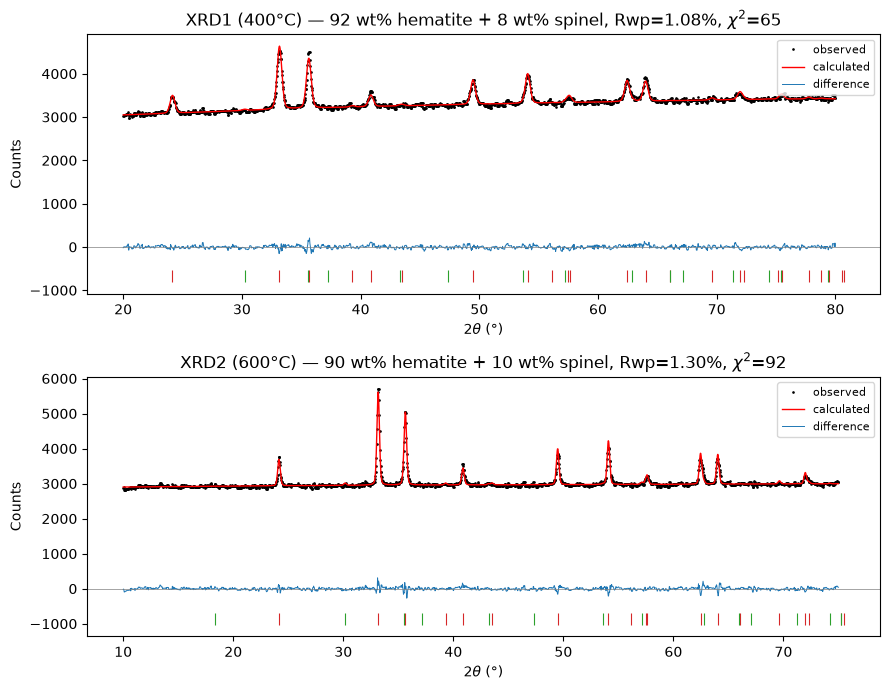

In [4]:
# Rietveld plot: obs / calc / difference + Bragg tick marks
fig, axes = plt.subplots(2, 1, figsize=(9, 7))
for ax, k in zip(axes, RAW):
    d = data[k]; ft = fits[k]
    tt, I = d['tt'], d['I']
    ax.plot(tt, I, 'k.', ms=1.8, label='observed')
    ax.plot(tt, ft['ycalc'], 'r-', lw=1.0, label='calculated')
    ax.plot(tt, I-ft['ycalc'], lw=0.7, color='tab:blue', label='difference')
    yb = -0.18*I.max()
    ph, ih, ps, isx = make_refiner(tt, I)[2](ft['q'][4], ft['q'][5])
    ax.vlines(ph, yb, yb+0.06*I.max(), color='tab:red', lw=0.8)
    ax.vlines(ps, yb, yb+0.06*I.max(), color='tab:green', lw=0.8)
    ax.axhline(0, color='gray', lw=0.5)
    ax.set_xlabel(r'$2\theta$ (°)'); ax.set_ylabel('Counts')
    ax.legend(fontsize=8, loc='upper right')
    ax.set_title(f"{k} — {ft['wH']:.0f} wt% hematite + {ft['wS']:.0f} wt% spinel, "
                 f"Rwp={ft['Rwp']:.2f}%, $\\chi^2$={ft['chi2']:.0f}")
fig.tight_layout(); fig.savefig(FIGS/'xrd_rietveld.png', dpi=200, bbox_inches='tight')
plt.show()

## 3. Crystallite size: Scherrer & Williamson–Hall (correct units)

$$D = \frac{K\lambda}{\beta\cos\theta}, \qquad \beta = \sqrt{\mathrm{FWHM}^2 - \beta_{inst}^2}$$

**Units**: λ in Å and β converted **degrees → radians** (×π/180) gives D in Å; ×0.1 → nm. (A previous version of this analysis converted with ×10 instead of ×0.1 ÷ rad, inflating every size by 1.745×; that bug is fixed here.)

W–H: $\beta\cos\theta = K\lambda/D + 4\varepsilon\sin\theta$ with β in radians.

In [5]:
HEM_PEAKS = [(24.16,'012'),(33.17,'104'),(35.64,'110'),(40.90,'006'),(49.48,'024'),
             (54.09,'214'),(57.62,'132'),(62.46,'300'),(64.02,'10-8'),(71.98,'134')]
K = 0.9

def gauss(x, A, mu, s, c): return A*np.exp(-0.5*((x-mu)/s)**2)+c

sizes = {}
for k in RAW:
    tt, I = data[k]['tt'], data[k]['I']
    # local background for peak fitting (display purposes)
    x = 2*(tt-tt.min())/(tt.max()-tt.min())-1
    Ib = I.copy()
    for _ in range(60):
        c = np.polyfit(x, Ib, 9); b = np.polyval(c, x); Ib = np.minimum(Ib, b)
    Inet = I - b
    rows = []
    for pos, hkl in HEM_PEAKS:
        m = (tt > pos-0.8) & (tt < pos+0.8)
        try:
            pop, _ = curve_fit(gauss, tt[m], Inet[m], p0=[Inet[m].max(), pos, 0.15, 0], maxfev=10000)
            A, mu, s, cc = pop
            FWHM = 2.3548*abs(s)
            if A <= 0 or not (1e-3 < FWHM < 2): continue
            beta_deg = math.sqrt(max(FWHM**2 - BINST**2, 1e-9))
            beta_rad = math.radians(beta_deg)
            th = math.radians(mu/2)
            D_nm = K*LAM/(beta_rad*math.cos(th))*0.1
            rows.append((hkl, mu, FWHM, beta_deg, beta_rad*math.cos(th), 4*math.sin(th)/LAM))
        except Exception:
            pass
    df = pd.DataFrame(rows, columns=['hkl','2theta','FWHM_deg','beta_deg','bcos','xWH'])
    df['D_nm'] = K*LAM/(np.radians(df.beta_deg)*np.cos(np.radians(df['2theta']/2)))*0.1
    sizes[k] = df
    print(f'\n== {k}'); print(df.round(3).to_string(index=False))
    print(f'Scherrer mean D = {df.D_nm.mean():.1f} ± {df.D_nm.std(ddof=1)/math.sqrt(len(df)):.1f} nm')
    A1, B1 = np.polyfit(df.xWH, df.bcos, 1)
    if A1 > 0:
        Dwh = K*LAM/A1*0.1
        n_ = len(df); res = df.bcos-(A1*df.xWH+B1); s2 = (res**2).sum()/(n_-2)
        Sxx = ((df.xWH-df.xWH.mean())**2).sum()
        dA = math.sqrt(s2/Sxx); dB = math.sqrt(s2*(1/n_+df.xWH.mean()**2/Sxx))
        print(f'W–H: D = {Dwh:.0f} ± {Dwh*dA/A1:.0f} nm, strain ε = {B1:.4f} ± {dB:.4f}')
    else:
        print('W–H: negative slope — size-dominated broadening, strain not resolvable')


== XRD1 (400°C)
 hkl  2theta  FWHM_deg  beta_deg  bcos   xWH   D_nm
 012  24.158     0.462     0.459 0.008 0.543 17.694
 104  33.161     0.486     0.483 0.008 0.741 17.162
 110  35.638     0.368     0.365 0.006 0.795 22.881
 006  40.876     0.449     0.447 0.007 0.907 18.983
 024  49.465     0.485     0.482 0.008 1.086 18.128
 214  54.076     0.489     0.487 0.008 1.180 18.323
 132  57.573     0.723     0.721 0.011 1.250 12.571
 300  62.463     0.471     0.468 0.007 1.346 19.836
10-8  64.009     0.444     0.441 0.007 1.376 21.244
 134  71.833     0.635     0.633 0.009 1.523 15.503
Scherrer mean D = 18.2 ± 0.9 nm
W–H: D = 139 ± 209 nm, strain ε = 0.0067 ± 0.0017

== XRD2 (600°C)
 hkl  2theta  FWHM_deg  beta_deg  bcos   xWH   D_nm
 012  24.152     0.232     0.227 0.004 0.543 35.866
 104  33.172     0.257     0.252 0.004 0.741 32.866
 110  35.632     0.256     0.251 0.004 0.794 33.302
 006  40.881     0.273     0.268 0.004 0.907 31.596
 024  49.496     0.307     0.303 0.005 1.087 28.872


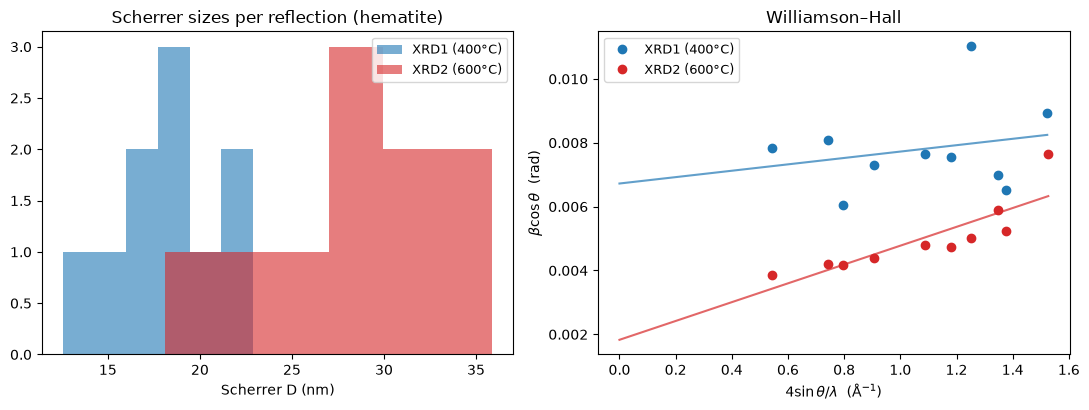

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
colors = {'XRD1 (400°C)':'tab:blue', 'XRD2 (600°C)':'tab:red'}
for k, df in sizes.items():
    a1.hist(df.D_nm, bins=6, alpha=.6, color=colors[k], label=k)
    a2.plot(df.xWH, df.bcos, 'o', color=colors[k], label=k)
    A1, B1 = np.polyfit(df.xWH, df.bcos, 1)
    xs = np.linspace(0, df.xWH.max(), 10)
    a2.plot(xs, A1*xs+B1, '-', color=colors[k], alpha=.7)
a1.set_xlabel('Scherrer D (nm)'); a1.legend(fontsize=9)
a1.set_title('Scherrer sizes per reflection (hematite)')
a2.set_xlabel(r'$4\sin\theta/\lambda$  (Å$^{-1}$)')
a2.set_ylabel(r'$\beta\cos\theta$  (rad)')
a2.legend(fontsize=9); a2.set_title('Williamson–Hall')
fig.tight_layout(); fig.savefig(FIGS/'xrd_size.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Summary

| | XRD1 (400 °C) | XRD2 (600 °C) |
|---|---|---|
| Phases | hematite + spinel | hematite + spinel |
| Rietveld wt% (hem/spin) | 92.0 / 8.0 | 90.2 / 9.8 |
| Rwp / χ² / GoF | 1.08% / 65 / 8.1 | 1.30% / 92 / 9.6 |
| a_hematite | 5.0359 Å | 5.0339 Å |
| a_spinel | 8.355 Å | 8.370 Å |
| FWHM (whole pattern) | 0.474° | 0.275° |
| Scherrer D | ≈ 19 nm | ≈ 28 nm |
| W–H | strain not resolvable | D ≈ 47 nm, ε ≈ 0.002 |

**Notes**
- Both samples are hematite-dominated with a minority spinel (~8–10 wt%); the spinel fraction increases slightly and crystallinity improves markedly with the 600 °C recalcination (FWHM halves).
- χ² ≫ 1 (GoF ≈ 8–10) is normal for lab powder data of this counting time: Rexp is very small because counts are high; the residuals come from profile-shape imperfections (single-FWHM pseudo-Voigt, no preferred-orientation or absorption correction), not from misassigned phases.
- If HighScore Plus gives somewhat different phase fractions/sizes: its refinement includes preferred orientation (March–Dollase), Thompson–Cox–Hastings profile with both Lorentzian size and strain terms, Kα2 duplication and sample-displacement corrections — all of which my minimal model fixes or omits. The hematite-dominance and the size increase 400→600 °C are robust either way.
- SEM grains (~130 nm) are ~5–7× the XRD crystallites: agglomerates of many coherently diffracting domains.